U fajlu “E-Commerce_Reviews_for_class.csv” su dati podaci sa komentarima kupaca jedne online prodavnice o kupljenoj odeci. Fajl sadrzi više kolona (varijabli) od kojih su za ovaj zadatak relevantne samo kolone Title i Review Text.
Koristeci podatke iz navedenog fajla, potrebno je uraditi sledece:
- Kreirati novu kolonu `review_content` koja objedinjuje sadrzaj kolona Title i Review Text (kroz obicno nadovezivanje stringova).
- Transformisati sadrzaj kolone review_content u vektorsku (tj numericku) reprezentaciju primenom pristupa zasnovanom na vektorima dokumenata (document vectors), i konkretno vektorskim reprezentacijama koje generise `“all-MiniLM-L12-v2”` Sentence Transformers model (model je lokalno dostupan).
- Izvrsiti klasterizaciju (transformisanih) novinskih tekstova primenom `aglomerativnog hijerarhijskog klasterovanja`. Odrediti optimalni broj klastera na osnovu `dendrograma i siluet skora` (silhouette score). Obrazloziti izbor optimalnog broja klastera.
- Za svaki od klastera odrediti top `10 reci/izraza` na osnovu `TF-IDF` metrike.
- Odrediti velicinu svakog od klastera i `opisati` svaki klaster na osnovu identifikovanih top 10 reci / izraza, i eventualnog uvida u naslove/sadrzaj komentara u okviru klastera.

In [1]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

import matplotlib.pyplot as plt

from pathlib import Path

import spacy

In [2]:
from sentence_transformers import SentenceTransformer

C:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
RAND_STATE = 1

MODEL = 'all-MiniLM-L12-v2'

#### UCITAVANJE I PREGLED PODATAKA

In [4]:
data = pd.read_csv(Path.cwd() / 'data' / 'E-Commerce_Reviews_for_class.csv')

data.head()

,Clothing ID,Age,Title,Review Text,Rating
0,833,50,More beautiful in person,I bought this in the store and love it. seeing...,4
1,1046,66,Wonderful,This wide leg pant gives the perception of a s...,5
2,945,23,Not for me,I ordered this with another sweater to compare...,4
3,1094,45,"For curvy or tall, not for the waist challenged","The fabric, so diaphanous! so flowy! the patte...",3
4,840,57,Comfortable,A nice rayon peasant shirt - like the sleeve l...,5


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Clothing ID  3000 non-null   int64 
 1   Age          3000 non-null   int64 
 2   Title        3000 non-null   object
 3   Review Text  3000 non-null   object
 4   Rating       3000 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 117.3+ KB


In [6]:
data.duplicated().sum()

np.int64(0)

#### KREIRANJE NOVE KOLONE

In [7]:
data['review_content'] = data.apply(lambda row: f"{row.Title}. {row['Review Text']}", axis=1)

data.head()

,Clothing ID,Age,Title,Review Text,Rating,review_content
0,833,50,More beautiful in person,I bought this in the store and love it. seeing...,4,More beautiful in person. I bought this in the...
1,1046,66,Wonderful,This wide leg pant gives the perception of a s...,5,Wonderful. This wide leg pant gives the percep...
2,945,23,Not for me,I ordered this with another sweater to compare...,4,Not for me. I ordered this with another sweate...
3,1094,45,"For curvy or tall, not for the waist challenged","The fabric, so diaphanous! so flowy! the patte...",3,"For curvy or tall, not for the waist challenge..."
4,840,57,Comfortable,A nice rayon peasant shirt - like the sleeve l...,5,Comfortable. A nice rayon peasant shirt - like...


In [8]:
data['word_count'] = data.review_content.apply(lambda x: len(x.split()))

data.word_count.describe()

count    3000.000000
mean       64.664333
std        28.621275
min         6.000000
25%        41.000000
50%        63.000000
75%        93.000000
max       118.000000
Name: word_count, dtype: float64

Model `'all-MiniLM-L12-v2'` prima 256 tokena, sto je 170 do 200 reci. U ovom datasetu, nijedan komentar ne prelazi tu granicu tako da je sve ok.

#### EMBEDDINGS

In [9]:
model = SentenceTransformer(MODEL)

# na kolokvijumu ce model biti dostupan lokalno, njegovo ucitavanje:
# model = SentenceTransformer('models/MODEL', local_files_only=True)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1677.28it/s]


In [10]:
review_embeddings = model.encode(data.review_content.to_numpy())

review_embeddings.shape

(3000, 384)

#### KOSINUSNA SLICNOST

In [11]:
review_similarities = cosine_similarity(review_embeddings, review_embeddings)

review_similarities.shape

(3000, 3000)

#### KOSINUSNA UDALJENOST

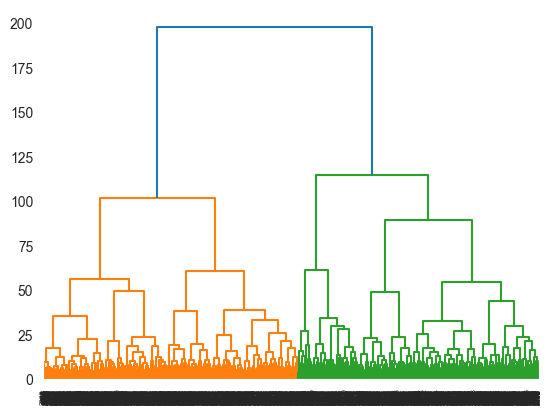

In [12]:
review_dist = 1 - review_similarities

ward_linkage = sch.linkage(review_dist, method='ward')

sch.dendrogram(ward_linkage)
plt.show()

Dendogram pokazuje da bi optimalan broj klastera bio `izmedju 2 i 5`. Iskoristicemo jos jednu metriku da bi proverili.

#### SILHOUETTE SCORE

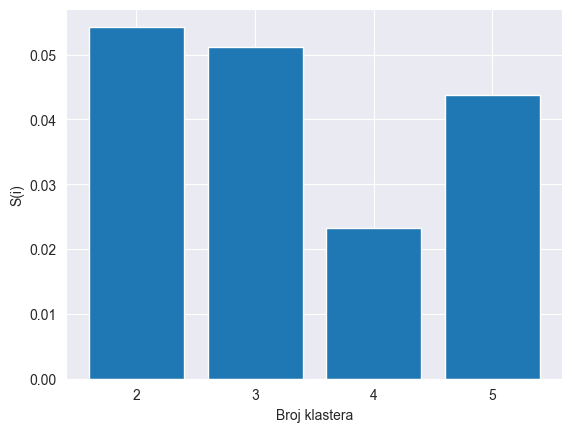

In [13]:
k_range = range(2, 6)

sil_scores = []

# uklanjanje malih negativnih udaljenosti zbog silhouette score-a
review_dist_clipped = np.clip(review_dist, a_min=0.0, a_max=None)

for k in k_range:
    clust = sch.fcluster(ward_linkage, t=k, criterion='maxclust')
    score = silhouette_score(review_dist_clipped, clust, metric='precomputed')
    sil_scores.append(score)

plt.bar(k_range, sil_scores)
plt.xlabel('Broj klastera')
plt.ylabel('S(i)')
plt.xticks(range(2, 6))
plt.show()

I po dendogramu i po silhouette score-u mozemo zakljuciti da je najoptimalniji broj klastera 2.

#### KLASTERIZACIJA

In [14]:
cluster_opt = sch.fcluster(ward_linkage, t=2, criterion='maxclust')

data['cluster'] = cluster_opt

data.cluster.value_counts()

cluster
1    1545
2    1455
Name: count, dtype: int64

Komentari kupaca su podjednako podeljeni po klasterima.

#### ODREDJIVANJE KLJUCNIH RECI

In [29]:
def get_top_ngrams(cluster_id, top_n=10, words_to_remove=None):
    vectorizer = TfidfVectorizer(
        stop_words='english',
        ngram_range=(2, 2),
        min_df=0.01,
        max_df=0.95
    )

    # svi komentari za izabrani klaster
    cluster_reviews = data.loc[data.cluster == cluster_id].review_content
    # racunanje tf-idf
    cluster_tfidf = vectorizer.fit_transform(cluster_reviews)
    # izvlacenje svih ngrama
    candidate_keywords = vectorizer.get_feature_names_out()
    # racunanje prosecnih tf-idf vrednosti za svaki ngram
    mean_tfidf = np.asarray(cluster_tfidf.mean(axis=1)).flatten()
    # ovde je axis=1 kolona, kod apply je 0
    sorted_candidates = sorted([(keyword, tfidf) for keyword, tfidf in zip(candidate_keywords, mean_tfidf)],
                               key=lambda x: x[1], reverse=True)

    if words_to_remove:
        sorted_candidates = [(kw, sc) for kw, sc in sorted_candidates if kw not in words_to_remove]

    return sorted_candidates[:top_n]

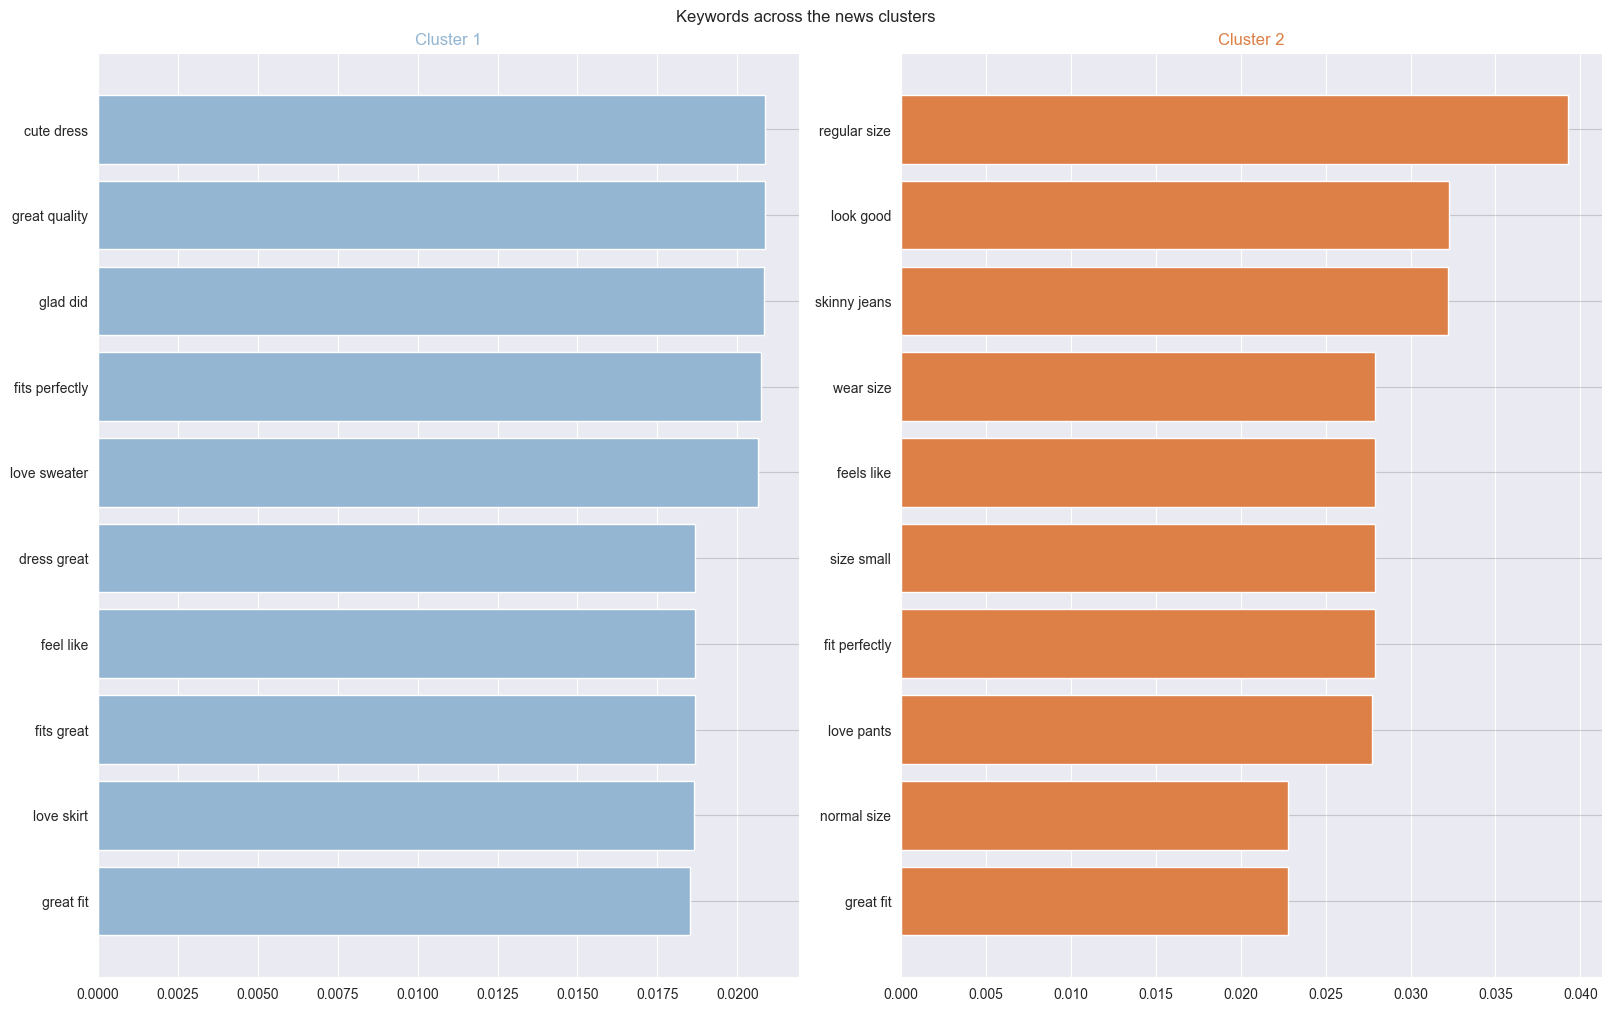

In [30]:
from pypalettes import load_cmap

fig, ax_grid = plt.subplots(nrows=1, ncols=2, figsize=(16, 10), constrained_layout=True)
axes = ax_grid.flatten()

cmap = load_cmap("excel_Median")

n_clust = data['cluster'].nunique()
for i in range(n_clust):
    scored_kwds = get_top_ngrams(i + 1)
    scored_kwds = sorted(scored_kwds, key=lambda item: item[1])
    scores = [s for kw, s in scored_kwds]
    keywords = [kw for kw, s in scored_kwds]

    axes[i].barh(keywords, scores, color=cmap(i))
    axes[i].set_title(f"Cluster {i + 1}", color=cmap(i))
    axes[i].grid(visible=True, axis='y', color='gray', alpha=0.35)

fig.suptitle("Keywords across the news clusters")

plt.show()

In [31]:
data.loc[data.cluster == 1].review_content.sample(10, random_state=RAND_STATE)

2567    Versatile comfortable dress. This dress is com...
958     Gingham garden dress renamed and new color. I ...
1249    Weird fit. I tried this on in the store and wa...
2430    Love it!. Love this jacket!!! it is soooo soft...
2483    So adorable!. I ordered my usual size s in the...
913     Very cute, short. This is very cute in person....
2386    Easy to wear!. Love this dress...light and com...
2628    Feels like comfy pajamas. The smocking is beau...
532     Great quality - runs narrow. I love this top! ...
526     Great little denim dress. Love this dress! it ...
Name: review_content, dtype: object

In [32]:
data.loc[data.cluster == 2].review_content.sample(10, random_state=RAND_STATE)

2798    Beautiful...runs very small. This bra is beaut...
2751    Sweater time. I have not worn yet but excited ...
2221    Every woman's cami. Looking for the perfect ca...
1888    Way too scratchy!. The minute i put this sweat...
92      Love these. These joggers are soo cute. they f...
2490    Gorgeous. Gosh, this is a beauty! maeve can be...
2597    Rip favorite pair. Lots of pairs of the pilcro...
224     This might be my new favorite!. I would of pai...
2594    Perfect pair!!. This pair of age stevie capris...
2301    Love this sweater..... Only negative thing is ...
Name: review_content, dtype: object

Na osnovu kljucnih reci i uzorka komentara mozemo dati grubu procenu o cemu se radi u svakom klasteru:
- Klaster 1: haljine i majice kojima su kupci uglavnom prezadovoljni
- Klaster 2: casual odeca, najvise farmerke/pantalone i dzemperi